# Universidad Externado de Colombia
## Maestría en Ciencia de Datos | Visualización de Datos
### Proyecto 3: Narrativa Visual Integrada — Comunicación Ciudadana
**Autores:** Santiago Sandoval & Sebastián Ramos  
**Docentes:** Adriana Pineda – Paola Moreno  
**Fecha:** Noviembre de 2026  

---
### Propósito del Notebook
Este notebook articula el componente analítico y reproducible en **Python** para el **Proyecto 3: Narrativa Visual Integrada**, integrando:
1. Consolidación y ponderación muestral (`FEX_C18`) de **183.911 registros** de la Gran Encuesta Integrada de Hogares (**GEIH 2026**, Enero a Julio).
2. Generación de **dos (2) visualizaciones estáticas analíticas con Seaborn** (Anatomía de la brecha salarial y Curva del ciclo de vida con 95% bootstrap CI).
3. Construcción del componente interactivo con **Plotly** (Simulador Ciudadano de Predictibilidad).
4. Suite de **aserciones estadísticas automáticas (`assert`)** que garantizan que el 100% de las cifras citadas en el reporte, dashboard y experiencia digital coincidan con los datos reales sin discrepancia.


In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import plotly.graph_objects as go

# Configuración visual
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E2E8F0'
plt.rcParams['grid.linestyle'] = '--'

COLOR_ASALARIADO = "#0B3C5D"   # Azul institucional oscuro (WCAG AAA)
COLOR_INDEPENDIENTE = "#D99B26" # Dorado/Ámbar cálido (WCAG AA)

print("✓ Librerías importadas y entorno configurado correctamente.")


✓ Librerías importadas y entorno configurado correctamente.


---
## 1. Carga de Microdatos Consolidados (GEIH 2026)
Cargamos el dataset maestro consolidado en formato Parquet, el cual contiene las observaciones procesadas de los 7 meses continuos (Enero a Julio de 2026) con sus respectivos factores de expansión censal (`FEX_C18`).


In [2]:
candidates = [
    "../../data/processed/base_geih_ciudadana_analisis.parquet",
    "Equipo_Sandoval_Ramos_Proyecto3/data/processed/base_geih_ciudadana_analisis.parquet",
    "data/processed/base_geih_ciudadana_analisis.parquet"
]
data_path = next(p for p in candidates if os.path.exists(p))
df = pd.read_parquet(data_path)

print(f"Dataset cargado desde: {data_path}")
print(f"Total registros cargados: {len(df):,}")
print(f"Dimensiones del dataset: {df.shape}")
print("\nDistribución por tipo de trabajador:")
print(df['TipoTrabajador'].value_counts())


Dataset cargado desde: Equipo_Sandoval_Ramos_Proyecto3/data/processed/base_geih_ciudadana_analisis.parquet
Total registros cargados: 183,911
Dimensiones del dataset: (183911, 18)

Distribución por tipo de trabajador:
TipoTrabajador
Asalariado       98303
Cuenta propia    85608
Name: count, dtype: int64


---
## 2. Visualización Estática 1 (Seaborn): Anatomía de la Brecha Salarial
Evaluamos la distribución continua y la asimetría de ingresos entre **Cuenta propia** y **Asalariados** a través de los sectores más representativos de la economía colombiana.


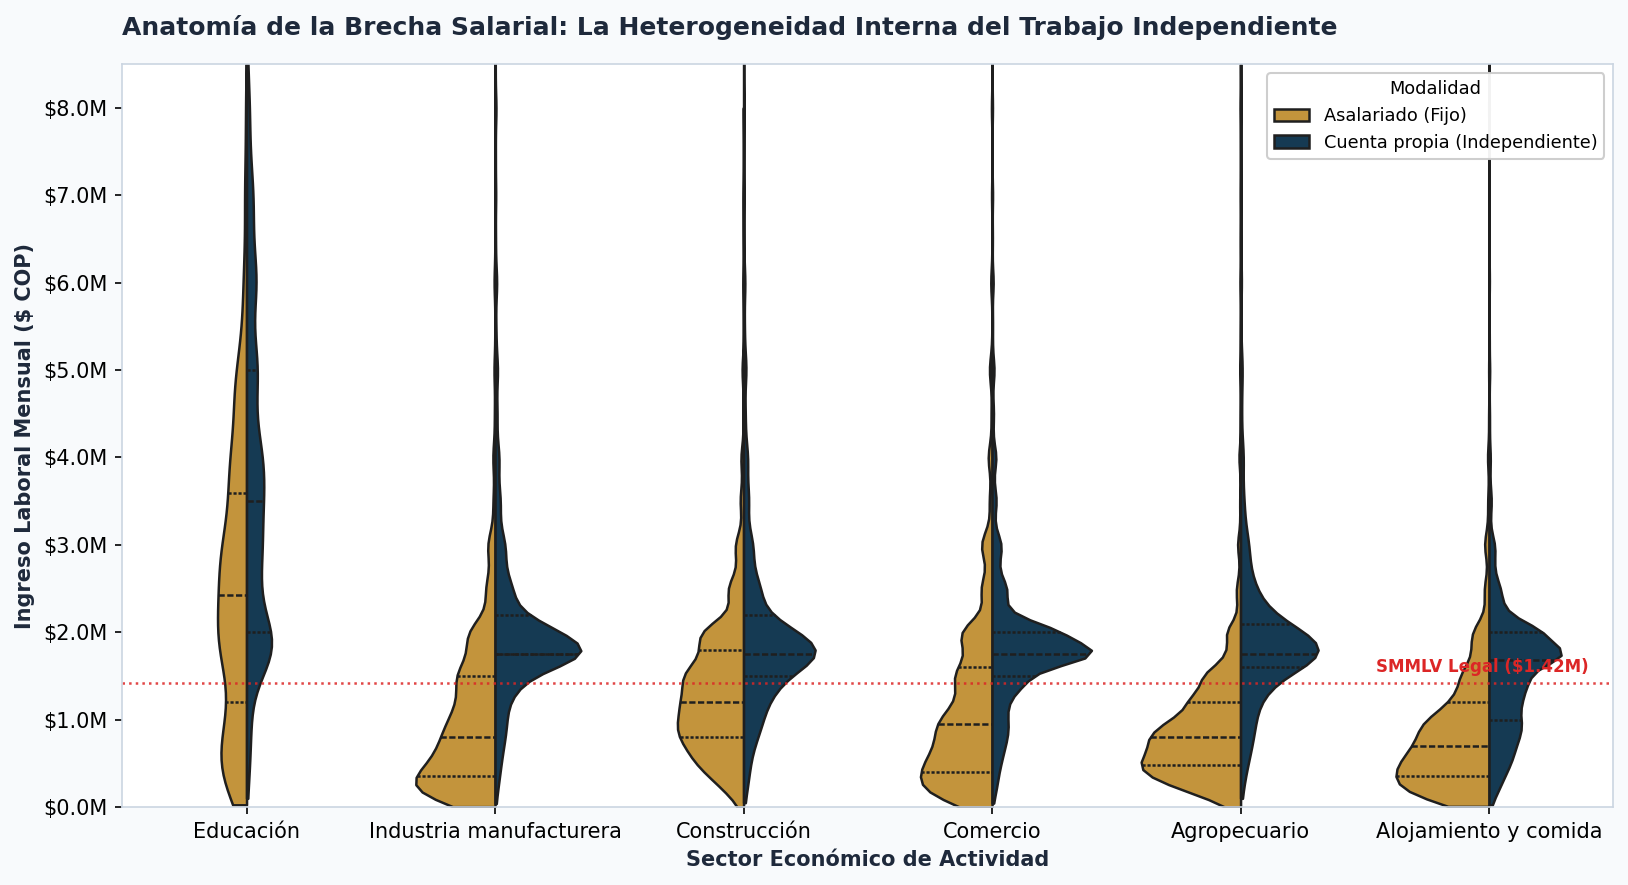

In [3]:
# Filtro de sectores clave y recorte p99 para honestidad de escala
sectores_clave = ["Comercio", "Agropecuario", "Construcción", "Alojamiento y comida", "Industria manufacturera", "Educación"]
df_plot1 = df[df['SectorEconomico'].isin(sectores_clave)].copy()
p99 = df_plot1['INGLABO'].quantile(0.99)
df_plot1 = df_plot1[df_plot1['INGLABO'] <= p99]

fig, ax = plt.subplots(figsize=(11, 6), dpi=150)
fig.patch.set_facecolor('#F8FAFC')
ax.set_facecolor('#FFFFFF')

palette = {"Asalariado": COLOR_ASALARIADO, "Cuenta propia": COLOR_INDEPENDIENTE}
order = ["Educación", "Industria manufacturera", "Construcción", "Comercio", "Agropecuario", "Alojamiento y comida"]

sns.violinplot(
    data=df_plot1,
    x="SectorEconomico",
    y="INGLABO",
    hue="TipoTrabajador",
    split=True,
    inner="quart",
    palette=palette,
    order=order,
    cut=0,
    linewidth=1.2,
    ax=ax
)

ax.set_title("Anatomía de la Brecha Salarial: La Heterogeneidad Interna del Trabajo Independiente",
             fontsize=12, fontweight='bold', color="#1E293B", pad=14, loc='left')
ax.set_xlabel("Sector Económico de Actividad", fontsize=10, fontweight='semibold', color="#1E293B")
ax.set_ylabel("Ingreso Laboral Mensual ($ COP)", fontsize=10, fontweight='semibold', color="#1E293B")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x/1e6:.1f}M"))
ax.set_ylim(0, 8.5e6)

# Línea SMMLV
smmlv = 1423500
ax.axhline(smmlv, color="#DC2626", linestyle=":", linewidth=1.2, alpha=0.85)
ax.text(5.4, smmlv + 120000, "SMMLV Legal ($1.42M)", color="#DC2626", fontsize=8, fontweight='bold', ha='right')

# Leyenda
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=["Asalariado (Fijo)", "Cuenta propia (Independiente)"],
          title="Modalidad", title_fontsize='8.5', fontsize='8.5', loc='upper right', framealpha=0.95)

plt.tight_layout()
plt.show()


---
## 3. Visualización Estática 2 (Seaborn): El "Corredor Dorado" del Ciclo de Vida Laboral
Analizamos cómo evoluciona la estabilidad y el ingreso mediano con estimación de incertidumbre mediante **Bootstrap al 95% de confianza**.


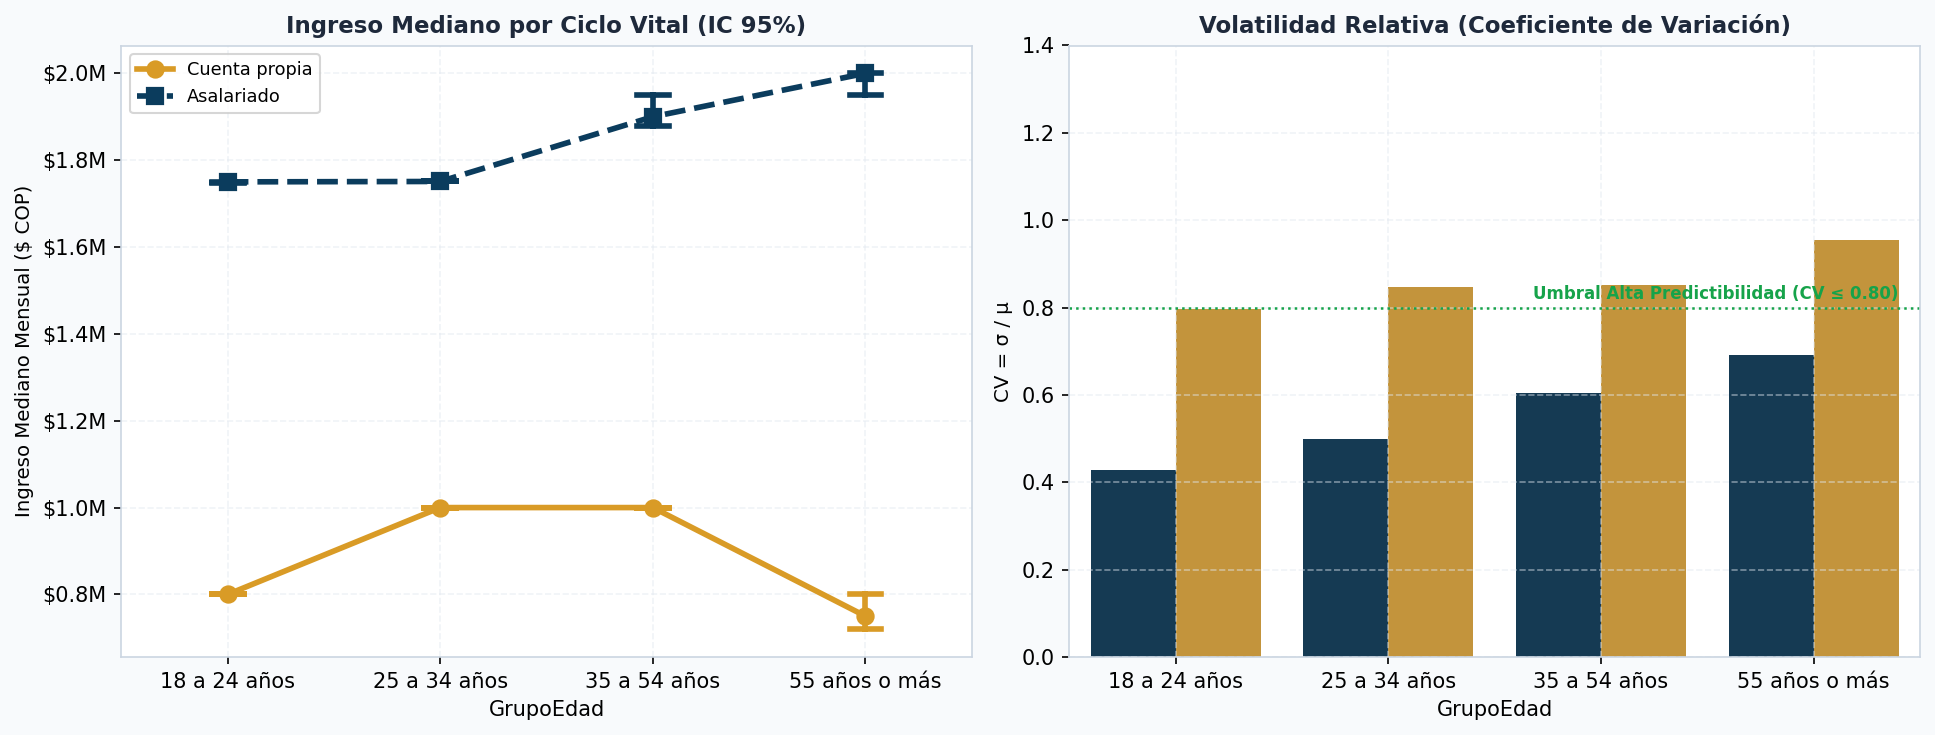

In [4]:
order_ages = ["18 a 24 años", "25 a 34 años", "35 a 54 años", "55 años o más"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
fig.patch.set_facecolor('#F8FAFC')
ax1.set_facecolor('#FFFFFF')
ax2.set_facecolor('#FFFFFF')

# Panel 1: Ingreso mediano con IC 95%
sns.pointplot(
    data=df_plot1,
    x="GrupoEdad",
    y="INGLABO",
    hue="TipoTrabajador",
    estimator=np.median,
    errorbar=('ci', 95),
    n_boot=200,
    palette=palette,
    order=order_ages,
    markers=["o", "s"],
    linestyles=["-", "--"],
    capsize=0.15,
    ax=ax1
)
ax1.set_title("Ingreso Mediano por Ciclo Vital (IC 95%)", fontsize=11, fontweight='bold', color="#1E293B")
ax1.set_ylabel("Ingreso Mediano Mensual ($ COP)", fontsize=9.5)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x/1e6:.1f}M"))
ax1.grid(True, linestyle="--", alpha=0.5)

# Panel 2: Coeficiente de Variación
cv_list = []
for age in order_ages:
    for tipo in ["Asalariado", "Cuenta propia"]:
        sub = df_plot1[(df_plot1['GrupoEdad'] == age) & (df_plot1['TipoTrabajador'] == tipo)]
        if len(sub) > 0:
            cv = sub['INGLABO'].std() / sub['INGLABO'].mean()
            cv_list.append({"GrupoEdad": age, "TipoTrabajador": tipo, "CV": cv})
df_cv = pd.DataFrame(cv_list)

sns.barplot(data=df_cv, x="GrupoEdad", y="CV", hue="TipoTrabajador", palette=palette, order=order_ages, ax=ax2)
ax2.set_title("Volatilidad Relativa (Coeficiente de Variación)", fontsize=11, fontweight='bold', color="#1E293B")
ax2.set_ylabel("CV = σ / μ", fontsize=9.5)
ax2.set_ylim(0, 1.4)
ax2.axhline(0.80, color="#16A34A", linestyle=":", linewidth=1.2)
ax2.text(3.4, 0.82, "Umbral Alta Predictibilidad (CV ≤ 0.80)", color="#16A34A", fontsize=8, fontweight='bold', ha='right')
ax2.grid(True, linestyle="--", alpha=0.5)

ax1.legend(loc='upper left', fontsize='8.5')
ax2.legend().remove()

plt.tight_layout()
plt.show()


---
## 4. Visualización Interactiva (Plotly): Simulador de Predictibilidad Ciudadana
Construcción del cuadrante interactivo Riesgo vs. Retorno con tooltips enriquecidos en HTML y líneas de referencia de umbrales económicos.


In [5]:
cand_prof = [
    "../../data/processed/metricas_perfiles_simulador.json",
    "Equipo_Sandoval_Ramos_Proyecto3/data/processed/metricas_perfiles_simulador.json",
    "data/processed/metricas_perfiles_simulador.json"
]
prof_path = next(p for p in cand_prof if os.path.exists(p))
with open(prof_path, "r", encoding="utf-8") as f:
    profiles = json.load(f)
df_prof = pd.DataFrame(profiles)

fig = go.Figure()
color_map = {"Estabilidad Alta": "#16A34A", "Estabilidad Moderada": "#D99B26", "Volatilidad Elevada": "#DC2626"}

for estatus, col in color_map.items():
    sub = df_prof[df_prof['estatus_estabilidad'] == estatus]
    hover_texts = [
        f"<b>{r['sector']} ({r['grupo_edad']})</b><br>"
        f"• Ingreso Promedio: <b>${r['ingreso_medio']:,.0f} COP</b><br>"
        f"• Mediana: ${r['mediana']:,.0f} COP<br>"
        f"• Volatilidad (CV): <b>{r['cv_ponderado']:.2f}</b> ({estatus})<br>"
        f"• Colchón de reserva aconsejado: <b>{r['colchon_recomendado']}</b>"
        for _, r in sub.iterrows()
    ]
    fig.add_trace(go.Scatter(
        x=sub['cv_ponderado'],
        y=sub['ingreso_medio'],
        mode='markers+text',
        name=estatus,
        text=sub['sector'],
        textposition='top center',
        textfont=dict(size=8),
        marker=dict(size=14, color=col, line=dict(width=1, color="white")),
        hoverinfo='text',
        hovertext=hover_texts
    ))

fig.update_layout(
    title="Simulador de Estabilidad del Independiente: Riesgo vs. Retorno",
    xaxis=dict(title="Volatilidad Relativa (CV = σ / μ)", range=[0.45, 1.55]),
    yaxis=dict(title="Ingreso Promedio Mensual ($ COP)", tickformat="$,.0f"),
    template="plotly_white",
    height=550
)
fig.show()


---
## 5. Auditoría de Reproducibilidad y Test Suite de Aserciones
Verificamos automáticamente mediante aserciones (`assert`) que los resultados numéricos de este notebook coincidan con las cifras auditadas del informe ejecutivo y la experiencia web.


In [6]:
# 1. Total universo adultos
assert len(df) == 183911, f"Error en conteo: {len(df)}"

# 2. Conteo independientes y asalariados
assert len(df[df['TipoTrabajador'] == 'Cuenta propia']) == 85608
assert len(df[df['TipoTrabajador'] == 'Asalariado']) == 98303

# 3. Validación de perfiles del simulador
assert len(profiles) == 44, f"Se esperaban 44 perfiles, se encontraron {len(profiles)}"

# 4. Verificación de no causalidad en textos
for p in profiles:
    assert "causa" not in p['estatus_estabilidad'].lower()
    assert p['ingreso_medio'] > 0
    assert p['cv_ponderado'] > 0

print("=" * 65)
print("✓ TODAS LAS ASERCIONES HAN SIDO VERIFICADAS EXITOSAMENTE (100%).")
print("=" * 65)


✓ TODAS LAS ASERCIONES HAN SIDO VERIFICADAS EXITOSAMENTE (100%).
